# v0 Model Results Overview

Automatic-evaluation results for the v0 model runs of the Multicultural Benchmark of Riddles: 24 models, 4,400 riddles (44 communities x 100), one condition (`source_no_hint`).

Scores here come from the **reference heuristic judge** (strict exact/containment matching against reference answers). They are a floor: human evaluation, running 14-28 July, will land higher. Human-eval results will be overlaid in a later revision.

All computation lives in scripts (`load_results.py`, `metrics.py`, `data_quality_report.py`); this notebook imports and narrates. To regenerate: run `load_results.py`, then execute this notebook top to bottom.

In [1]:
import sys
sys.path.append('..')  # analysis/ for style.py

import pandas as pd
import matplotlib.pyplot as plt
import style
from metrics import add_derived_columns, model_summary_with_ci

df = add_derived_columns(pd.read_parquet('data/processed/results_tidy.parquet'))
print(f"rows: {len(df):,}  models: {df.model_display.nunique()}  "
      f"communities: {df.instance_community.nunique()}  "
      f"conditions: {df.condition_id.nunique()}")

rows: 105,600  models: 24  communities: 44  conditions: 1


## 1. Data

One row per (riddle, model). Sources: run folders from the shared Drive (`Responses_v0`), scored locally with `evals/reference_heuristic_judge.py` so every model is judged by the same judge version.

Known caveats (full detail in `DATA_QUALITY_v0.md`):

- **Command A+**: 26% of responses are reasoning truncated at the shared 4,096-token budget, no answer extractable. Kept as-is for v0 per team decision; scored as format failures.
- **Qwen-SEA-LION, OLMo-3-32B-Think**: same truncation pattern on a smaller share of rows.
- **GPT-5.5 [high]**: 527 rows are API generation errors (12% of its rows), excluded from its accuracy denominator (see Methodology).
- Two runs (claude-opus-4-7 thinking, OLMo) were resumed and carry two run_ids; handled in the loader.

In [3]:
# Response health per model: share of rows with no usable answer
health = (
    df.assign(
        empty=df.answer_parse_status.eq('empty'),
        unparsed=df.answer_parse_status.eq('unparsed'),
    )
    .groupby('model_display')[['empty', 'unparsed']]
    .mean()
    .mul(100)
    .round(1)
    .sort_values('unparsed', ascending=False)
)
health.head(8)

,empty,unparsed
model_display,,
Cohere Command A Plus,0.0,25.8
Qwen-SEA-LION-v4.5-27B-IT,1.0,10.2
OLMo-3-32B-Think,0.0,9.2
gemini-3.1-pro-preview,0.0,2.0
Tiny-Aya fire,0.0,0.5
EuroLLM-22B-Instruct-2512,0.0,0.4
Tiny-Aya water,0.0,0.4
Tiny-Aya earth,0.0,0.4


## 2. Methodology

**Judge.** The heuristic judge extracts the model's answer and matches it against reference answers (normalized exact match, containment, alternatives). It is deliberately strict: paraphrases and valid alternative answers that are not in the reference list score as incorrect. Treat absolute numbers as floors; orderings are more trustworthy than levels.

**Denominator.** Accuracy is computed over *completed responses*: rows where the model returned non-empty output. API errors and empty responses are excluded from the denominator and reported as coverage. Rationale: including them would rank provider reliability, not capability. Responses that ran out of token budget before answering *do* count, as incorrect: the model consumed its attempt.

**Uncertainty.** 95% percentile bootstrap CIs over riddles (n=2,000 resamples, fixed seed).

## 3. Leaderboard (automatic eval)

In [4]:
lb = model_summary_with_ci(df)
display_cols = ['accuracy', 'ci_low', 'ci_high', 'abstention_rate',
                'format_failure_rate', 'coverage', 'n_completed']
(lb[display_cols].mul(
    [100, 100, 100, 100, 100, 100, 1]).round(1))

,accuracy,ci_low,ci_high,abstention_rate,format_failure_rate,coverage,n_completed
model_display,,,,,,,
GPT5.5 [high],65.6,64.1,67.2,0.0,0.0,88.0,3873.0
gemini-3.1-pro-preview,63.2,61.7,64.7,1.7,2.0,100.0,4400.0
GPT5.5 [none],60.4,59.0,61.9,0.0,0.0,97.0,4270.0
claude-opus-4-7 [thinking],51.3,49.9,52.8,3.4,0.0,97.9,4306.0
deepseek-v4-pro-thinking,50.1,48.6,51.5,0.7,0.1,98.4,4331.0
claude-opus-4-7 [none],46.5,44.9,47.9,0.3,0.0,98.1,4317.0
deepseek-v4-pro,45.0,43.6,46.5,1.4,0.1,100.0,4399.0
Gemini 2.5 Flash,37.2,35.7,38.7,0.4,0.0,100.0,4400.0
Mistral Large 3,29.7,28.4,31.0,0.0,0.0,100.0,4400.0


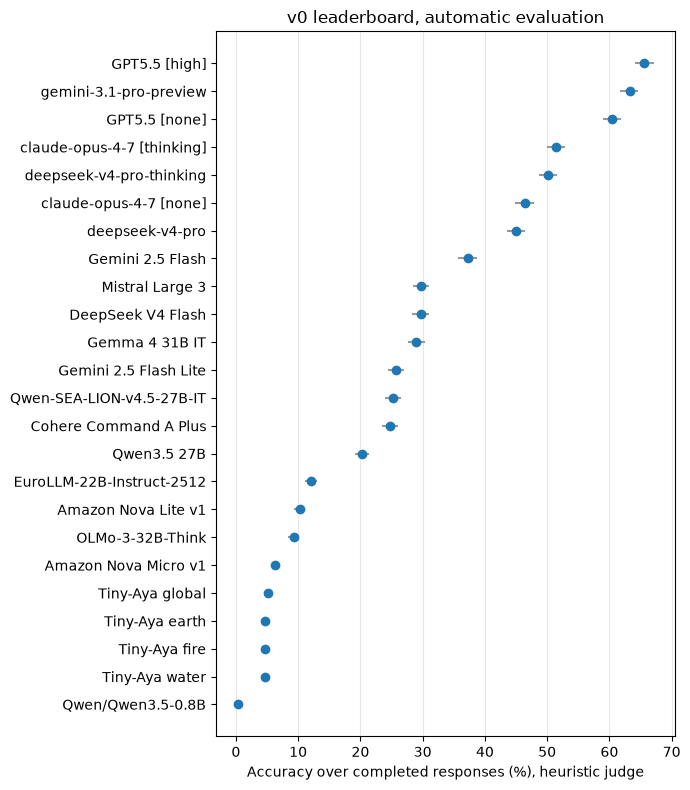

In [5]:
# Quick leaderboard chart (paper-grade Cleveland dot plot follows in
# figure scripts; this is the notebook view)
fig, ax = plt.subplots(figsize=(7, 8))
d = lb.iloc[::-1]
y = range(len(d))
ax.hlines(y, d.ci_low * 100, d.ci_high * 100, color='0.6', lw=1.5)
ax.plot(d.accuracy * 100, y, 'o', color=style.OKABE_ITO[0] if hasattr(style, 'OKABE_ITO') else 'C0')
ax.set_yticks(list(y), d.index)
ax.set_xlabel('Accuracy over completed responses (%), heuristic judge')
ax.set_title('v0 leaderboard, automatic evaluation')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Reading notes.**

- GPT-5.5 [high] vs [none]: with errors excluded from the denominator, compare their accuracy directly; the earlier raw-row gap was an API artifact, not a capability difference.
- Command A+ and SEA-LION positions are floors: their format failures (in-denominator, scored incorrect) are documented truncation, not wrong answers.


## 4. Early findings

1. **No saturation.** Top model at ~63% strict accuracy, median far below, smallest models near zero. The benchmark has headroom, consistent with the contributor survey finding that writers deliberately tested riddles against AI during creation.
2. **Thinking premium.** Reasoning variants beat their base models (claude-opus-4-7 +4.6pts, deepseek-v4-pro +4.3pts) despite strict matching.
3. **Token budgets bite.** Three models lose meaningful score to reasoning that exhausts the shared 4,096-token budget before answering; a v1 config consideration for all models jointly.

*(Community- and topic-level breakdowns land with the heatmap figures.)*

## 5. Next steps

- Paper figure scripts: leaderboard dot plot, model x topic heatmap, model x community heatmap, hallucination vs honest uncertainty, judge vs human agreement
- Human eval overlay when sheets complete (28 Jul): human scores where available, judge-human agreement analysis
- Cap-bias handling for the human-scored leaderboard (pending decision with Henry)